<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/mathematical_biology/mathbio_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Mathematical Biology* — `mathbio_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# MathBio Ch 2 Figures — Colab Notebook
**Mathematical Biology · Chapter 2: Discrete Time**

PSE Lab · SeoulTech · Tong (Cambridge)

Figures saved to `figures/ch02/`. Run each cell independently.

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | Cobweb, stability, period-doubling onset | §2.1–2.2 |
| fig02 | Bifurcation diagram, Lyapunov, sensitive dependence | §2.2 |
| fig03 | Feigenbaum $\delta$, universality, RG analogy table | §2.3 |
| fig04 | Period-3 window, self-similarity, orbit | §2.2 |
| fig05 | RG fixed point function $g^*$, interval shrinking | §2.3 |

---
## fig01 · Cobweb & Stability (§2.1–2.2)

**Left**: Cobweb diagram — stable FP ($r=2.5$), 2-cycle ($r=3.3$), chaos ($r=3.9$). **Centre**: $|f'(x^*)|=|2-r|$ — stable for $1<r<3$. **Right**: Orbit diagram zoom near period-doubling onset.

  saved -> figures/ch02/fig01_fixedpts_cobweb.png


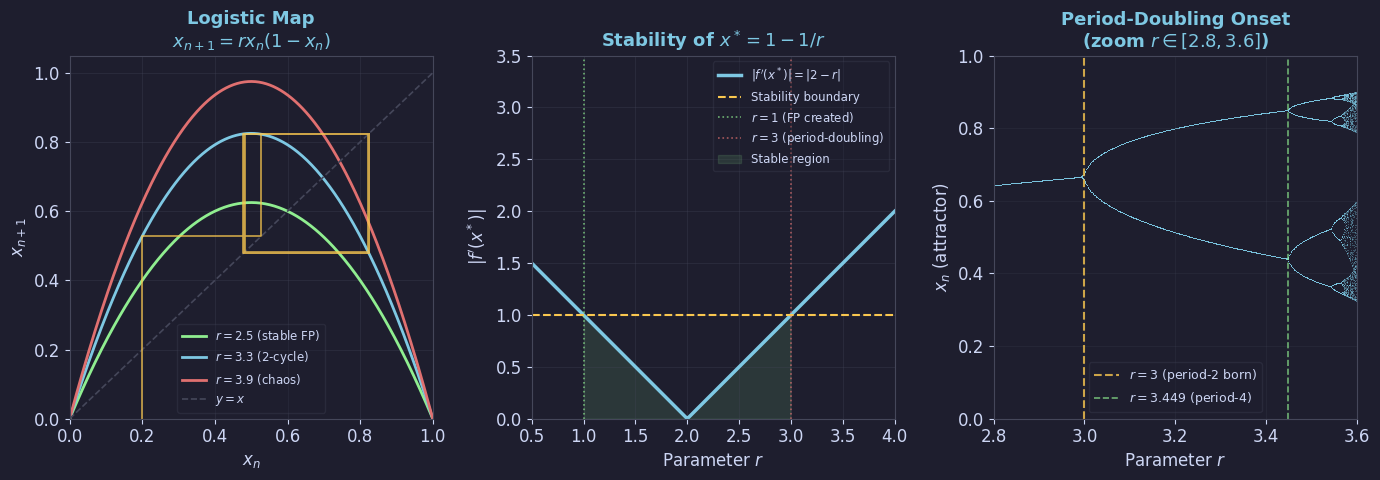

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01: Cobweb, stability, period-doubling onset (§2.1-2.2) ────────────
def cobweb(ax, r, x0=0.2, n=50):
    x = x0; xs, ys = [x], [0]
    for _ in range(n):
        y = r*x*(1-x); xs += [x,y]; ys += [y,y]; x = y
    ax.plot(xs, ys, color=YELLOW, lw=1.2, alpha=0.8)

x_arr = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

ax = axes[0]
for r_val,col,lab in [(2.5,GREEN,r'$r=2.5$ (stable FP)'),
                       (3.3,BLUE,r'$r=3.3$ (2-cycle)'),
                       (3.9,RED,r'$r=3.9$ (chaos)')]:
    ax.plot(x_arr, r_val*x_arr*(1-x_arr), color=col, lw=2.0, label=lab)
ax.plot(x_arr, x_arr, color=EDGE, lw=1.2, ls='--', label='$y=x$')
cobweb(ax, 3.3, 0.2, 50)
ax.set_xlabel('$x_n$'); ax.set_ylabel('$x_{n+1}$')
ax.set_title('Logistic Map\n'+r'$x_{n+1}=rx_n(1-x_n)$', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG); ax.grid(True)
ax.set_xlim(0,1); ax.set_ylim(0,1.05)

r_arr = np.linspace(0.5,4,300); fp_stab = np.abs(2-r_arr)
ax2 = axes[1]
ax2.plot(r_arr, fp_stab, color=BLUE, lw=2.5, label=r"$|f'(x^*)| = |2-r|$")
ax2.axhline(1,color=YELLOW,lw=1.5,ls='--',label="Stability boundary")
ax2.axvline(1,color=GREEN,lw=1.2,ls=':',alpha=0.7,label='$r=1$ (FP created)')
ax2.axvline(3,color=RED,lw=1.2,ls=':',alpha=0.7,label='$r=3$ (period-doubling)')
ax2.fill_between(r_arr,fp_stab,0,where=(fp_stab<1)&(r_arr>1),
                 color=GREEN,alpha=0.12,label='Stable region')
ax2.set_xlabel('Parameter $r$'); ax2.set_ylabel(r"$|f'(x^*)|$")
ax2.set_title(r'Stability of $x^*=1-1/r$', color=BLUE)
ax2.legend(fontsize=8.5,labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0.5,4); ax2.set_ylim(0,3.5)

ax3 = axes[2]
r_vals2 = np.linspace(2.8,3.6,500)
x=0.5*np.ones(len(r_vals2)); xb=[]; rb=[]
for _ in range(400): x=r_vals2*x*(1-x)
for _ in range(100): x=r_vals2*x*(1-x); xb.extend(x); rb.extend(r_vals2)
ax3.scatter(rb,xb,s=0.3,c=BLUE,alpha=0.4,linewidths=0)
ax3.axvline(3.0,color=YELLOW,lw=1.5,ls='--',alpha=0.8,label='$r=3$ (period-2 born)')
ax3.axvline(3.449,color=GREEN,lw=1.2,ls='--',alpha=0.7,label='$r=3.449$ (period-4)')
ax3.set_xlabel('Parameter $r$'); ax3.set_ylabel('$x_n$ (attractor)')
ax3.set_title('Period-Doubling Onset\n(zoom $r\\in[2.8,3.6]$)', color=BLUE)
ax3.legend(fontsize=9,labelcolor=FG); ax3.grid(True,alpha=0.2)
ax3.set_xlim(2.8,3.6); ax3.set_ylim(0,1)
plt.tight_layout(pad=1.2)
save('fig01_fixedpts_cobweb.png', fig)


---
## fig02 · Bifurcation Diagram & Lyapunov (§2.2)

**Left**: Full bifurcation diagram — period-doubling cascade. **Centre**: Lyapunov exponent $\lambda$ — chaos when $\lambda>0$. **Right**: Sensitive dependence — two orbits with $\Delta x_0=10^{-4}$ diverge after ~20 steps.

  saved -> figures/ch02/fig02_bifurcation_lyapunov.png


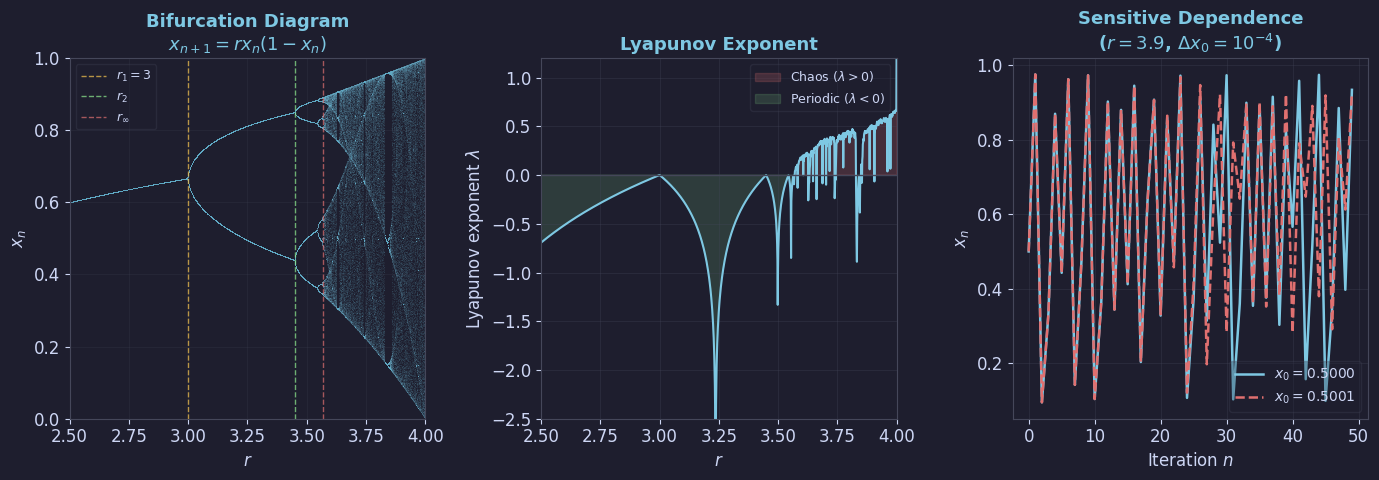

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02: Bifurcation diagram + Lyapunov + sensitive dependence (§2.2) ───
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

ax = axes[0]
r_vals=np.linspace(2.5,4.0,1500); x=0.5*np.ones(len(r_vals)); xb=[]; rb=[]
for _ in range(500): x=r_vals*x*(1-x)
for _ in range(200): x=r_vals*x*(1-x); xb.extend(x); rb.extend(r_vals)
ax.scatter(rb,xb,s=0.08,c=BLUE,alpha=0.25,linewidths=0)
for rv,col,lab in [(3.0,YELLOW,'$r_1=3$'),(3.449,GREEN,'$r_2$'),(3.5699,RED,r'$r_\infty$')]:
    ax.axvline(rv,color=col,lw=1.0,ls='--',alpha=0.7,label=lab)
ax.set_xlabel('$r$'); ax.set_ylabel('$x_n$')
ax.set_title('Bifurcation Diagram\n'+r'$x_{n+1}=rx_n(1-x_n)$', color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True,alpha=0.2)
ax.set_xlim(2.5,4.0); ax.set_ylim(0,1)

ax2 = axes[1]
r_lya=np.linspace(2.5,4.0,1200); lya=np.zeros_like(r_lya)
for i,ri in enumerate(r_lya):
    xl=0.5; lam=0.0
    for _ in range(500): xl=ri*xl*(1-xl)
    for _ in range(500):
        xl=ri*xl*(1-xl); der=abs(ri*(1-2*xl))
        if der>0: lam+=np.log(der)
    lya[i]=lam/500
ax2.plot(r_lya,lya,color=BLUE,lw=1.5)
ax2.axhline(0,color=EDGE,lw=1.0)
ax2.fill_between(r_lya,lya,0,where=(lya>0),color=RED,alpha=0.2,label='Chaos ($\\lambda>0$)')
ax2.fill_between(r_lya,lya,0,where=(lya<0),color=GREEN,alpha=0.15,label='Periodic ($\\lambda<0$)')
ax2.set_xlabel('$r$'); ax2.set_ylabel('Lyapunov exponent $\\lambda$')
ax2.set_title('Lyapunov Exponent', color=BLUE)
ax2.legend(fontsize=9,labelcolor=FG); ax2.grid(True)
ax2.set_xlim(2.5,4.0); ax2.set_ylim(-2.5,1.2)

ax3 = axes[2]
r_c=3.9; x1,x2=0.5,0.5001
t_arr=np.arange(50); traj1=[x1]; traj2=[x2]
for _ in range(49):
    x1=r_c*x1*(1-x1); traj1.append(x1)
    x2=r_c*x2*(1-x2); traj2.append(x2)
ax3.plot(t_arr,traj1,color=BLUE,lw=1.8,label='$x_0=0.5000$')
ax3.plot(t_arr,traj2,color=RED,lw=1.8,ls='--',label='$x_0=0.5001$')
ax3.set_xlabel('Iteration $n$'); ax3.set_ylabel('$x_n$')
ax3.set_title('Sensitive Dependence\n($r=3.9$, $\\Delta x_0=10^{-4}$)', color=BLUE)
ax3.legend(fontsize=10,labelcolor=FG); ax3.grid(True)
plt.tight_layout(pad=1.2)
save('fig02_bifurcation_lyapunov.png', fig)


---
## fig03 · Feigenbaum Universality (§2.3)

**Left**: Ratios converging to $\delta\approx4.669$. **Centre**: Logistic and sine maps have identical structure after rescaling. **Right**: RG analogy table — map period-doubling ↔ SFT renormalisation group.

  saved -> figures/ch02/fig03_feigenbaum.png


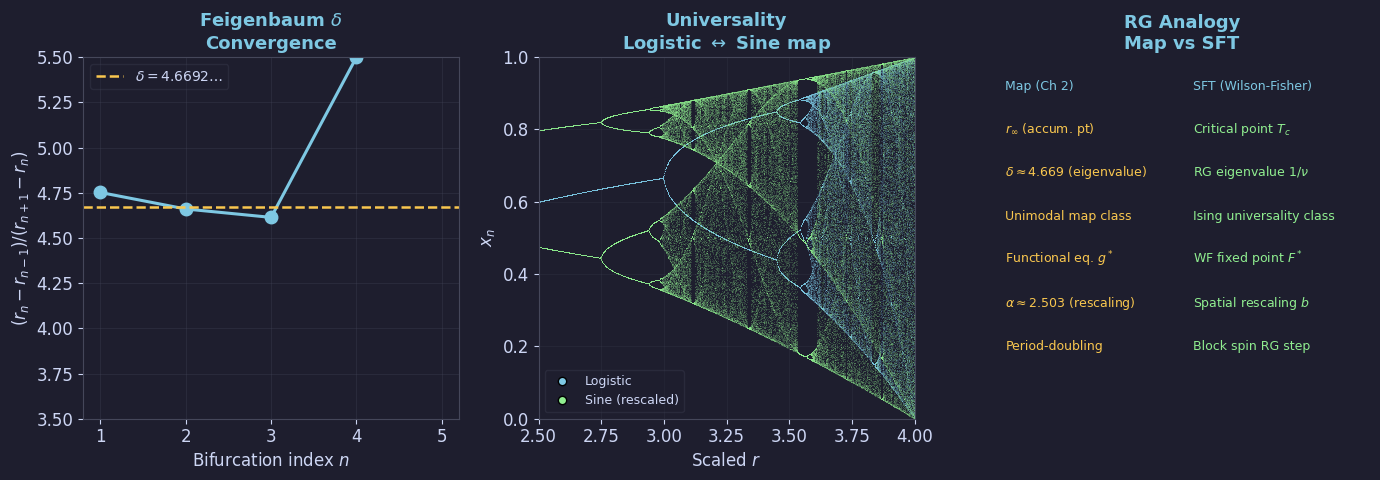

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03: Feigenbaum delta + universality + RG table (§2.3) ─────────────
r_n=[3.0,3.4495,3.5441,3.5644,3.5688,3.5696,3.56969]
deltas=[(r_n[i]-r_n[i-1])/(r_n[i+1]-r_n[i]) for i in range(1,len(r_n)-1)]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

ax=axes[0]
ax.plot(range(1,len(deltas)+1),deltas,color=BLUE,lw=2.2,marker='o',ms=9)
ax.axhline(4.6692,color=YELLOW,lw=1.8,ls='--',label=r'$\delta=4.6692\ldots$')
ax.set_xlabel('Bifurcation index $n$')
ax.set_ylabel(r'$(r_n-r_{n-1})/(r_{n+1}-r_n)$')
ax.set_title('Feigenbaum $\\delta$\nConvergence', color=BLUE)
ax.legend(loc="upper left", fontsize=10,labelcolor=FG); ax.grid(True); ax.set_ylim(3.5,5.5)

ax2=axes[1]
r_log=np.linspace(2.5,4.0,800)
xl=0.5*np.ones(len(r_log)); xbl=[]; rbl=[]
for _ in range(500): xl=r_log*xl*(1-xl)
for _ in range(150): xl=r_log*xl*(1-xl); xbl.extend(xl); rbl.extend(r_log)
ax2.scatter(np.array(rbl),np.array(xbl),s=0.08,c=BLUE,alpha=0.2,linewidths=0.5,label='Logistic')
r_sin=np.linspace(0.8,1.0,800)
xs=0.5*np.ones(len(r_sin)); xbs=[]; rbs=[]
for _ in range(500): xs=r_sin*np.sin(np.pi*xs)
for _ in range(150): xs=r_sin*np.sin(np.pi*xs); xbs.extend(xs); rbs.extend(r_sin)
r_sin_sc=(np.array(rbs)-0.8)/0.2*1.5+2.5
ax2.scatter(r_sin_sc,np.array(xbs),s=0.08,c=GREEN,alpha=0.2,linewidths=0.5,label='Sine (rescaled)')
ax2.set_xlabel('Scaled $r$'); ax2.set_ylabel('$x_n$')
ax2.set_title('Universality\nLogistic $\\leftrightarrow$ Sine map', color=BLUE)

legend_elements = [
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor=BLUE, markersize=6, label='Logistic'),
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor=GREEN, markersize=6, label='Sine (rescaled)')
]

ax2.legend(handles=legend_elements, fontsize=9, labelcolor=FG)
ax2.grid(True,alpha=0.2)
ax2.set_xlim(2.5,4.0); ax2.set_ylim(0,1)

ax3=axes[2]
ax3.axis('off')
ax3.set_title('RG Analogy\nMap vs SFT', color=BLUE)
rows=[('Map (Ch 2)','SFT (Wilson-Fisher)'),
      (r'$r_\infty$ (accum. pt)','Critical point $T_c$'),
      (r'$\delta\approx4.669$ (eigenvalue)','RG eigenvalue $1/\\nu$'),
      ('Unimodal map class','Ising universality class'),
      ('Functional eq. $g^*$','WF fixed point $F^*$'),
      (r'$\alpha\approx2.503$ (rescaling)','Spatial rescaling $b$'),
      ('Period-doubling','Block spin RG step')]
y0=0.92; dy=0.12
for i,(left,right) in enumerate(rows):
    lc=BLUE if i==0 else YELLOW; rc=BLUE if i==0 else GREEN
    ax3.text(0.03,y0-i*dy,left,transform=ax3.transAxes,
             fontsize=9,color=lc,va='center')
    ax3.text(0.53,y0-i*dy,right,transform=ax3.transAxes,
             fontsize=9,color=rc,va='center')
plt.tight_layout(pad=1.2)
save('fig03_feigenbaum.png', fig)


---
## fig04 · Period-3 Window & Self-Similarity (§2.2)

**Left**: Orbit diagram showing period-3 window. **Centre**: Zoom inside period-3 window — complete bifurcation diagram within. **Right**: Period-3 time series $f^3(x^*)=x^*$.

/tmp/ipykernel_17011/5577152.py:23: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)


  saved -> figures/ch02/fig04_period3.png


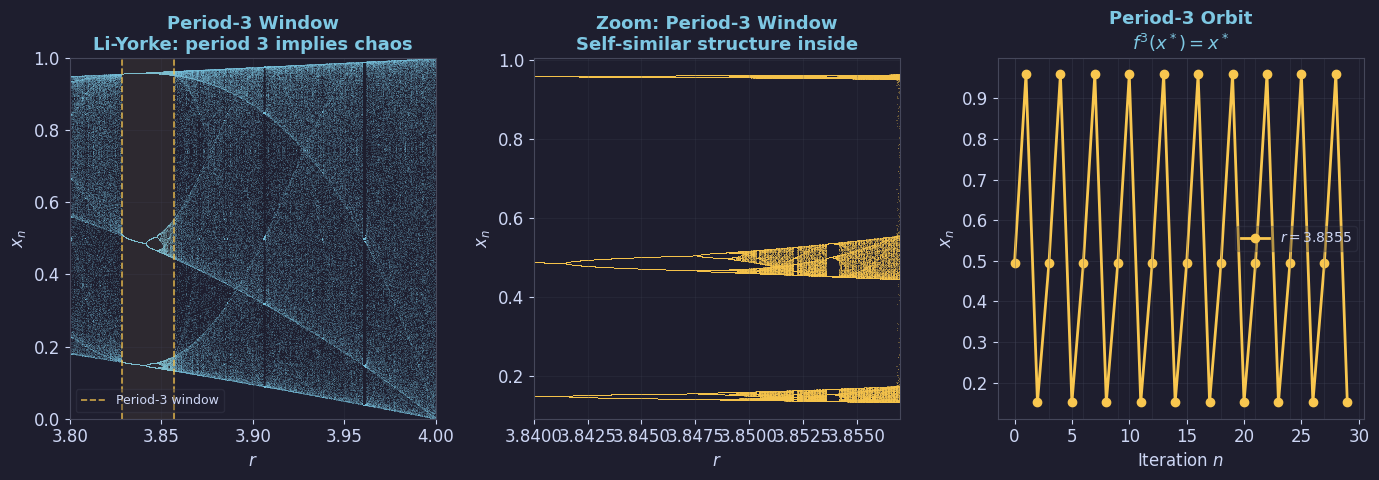

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04: Period-3 window and self-similarity (§2.2) ─────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

ax=axes[0]
r2=np.linspace(3.8,4.0,800); x2=0.5*np.ones(len(r2)); xb2=[]; rb2=[]
for _ in range(500): x2=r2*x2*(1-x2)
for _ in range(200): x2=r2*x2*(1-x2); xb2.extend(x2); rb2.extend(r2)
ax.scatter(rb2,xb2,s=0.2,c=BLUE,alpha=0.3,linewidths=0)
ax.axvline(3.8284,color=YELLOW,lw=1.2,ls='--',alpha=0.8,label='Period-3 window')
ax.axvline(3.857,color=YELLOW,lw=1.2,ls='--',alpha=0.8)
ax.fill_between([3.8284,3.857],[0,0],[1,1],color=YELLOW,alpha=0.07)
ax.set_xlabel('$r$'); ax.set_ylabel('$x_n$')
ax.set_title('Period-3 Window\nLi-Yorke: period 3 implies chaos', color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True,alpha=0.2)
ax.set_xlim(3.8,4.0); ax.set_ylim(0,1)

ax2=axes[1]
r3=np.linspace(3.84,3.857,600); x3=0.5*np.ones(len(r3)); xb3=[]; rb3=[]
for _ in range(500): x3=r3*x3*(1-x3)
for _ in range(300): x3=r3*x3*(1-x3); xb3.extend(x3); rb3.extend(r3)
ax2.scatter(rb3,xb3,s=0.3,c=YELLOW,alpha=0.4,linewidths=0)
ax2.set_xlabel('$r$'); ax2.set_ylabel('$x_n$')
ax2.set_title('Zoom: Period-3 Window\nSelf-similar structure inside', color=BLUE)
ax2.grid(True,alpha=0.2); ax2.set_xlim(3.84,3.857)

ax3=axes[2]
r_p3=3.8355; xp=0.5
for _ in range(200): xp=r_p3*xp*(1-xp)
traj=[];
for _ in range(30): xp=r_p3*xp*(1-xp); traj.append(xp)
ax3.plot(range(30),traj,color=YELLOW,lw=2.0,marker='o',ms=6,label='$r=3.8355$')
for i in range(0,30,3): ax3.axvline(i,color=EDGE,lw=0.5,alpha=0.4)
ax3.set_xlabel('Iteration $n$'); ax3.set_ylabel('$x_n$')
ax3.set_title('Period-3 Orbit\n$f^3(x^*)=x^*$', color=BLUE)
ax3.legend(fontsize=10,labelcolor=FG); ax3.grid(True)
plt.tight_layout(pad=1.2)
save('fig04_period3.png', fig)


---
## fig05 · RG Fixed Point Function (§2.3)

**Left**: Convergence of rescaled maps $g_0, g_1\to g^*$ satisfying $\alpha g^*(x)=g^*(g^*(-x/\alpha))$. **Centre**: $|\delta_n-\delta|\to0$ — rate of convergence. **Right**: Bifurcation intervals shrinking by $\delta$ each step.

  saved -> figures/ch02/fig05_rg_feigenbaum.png


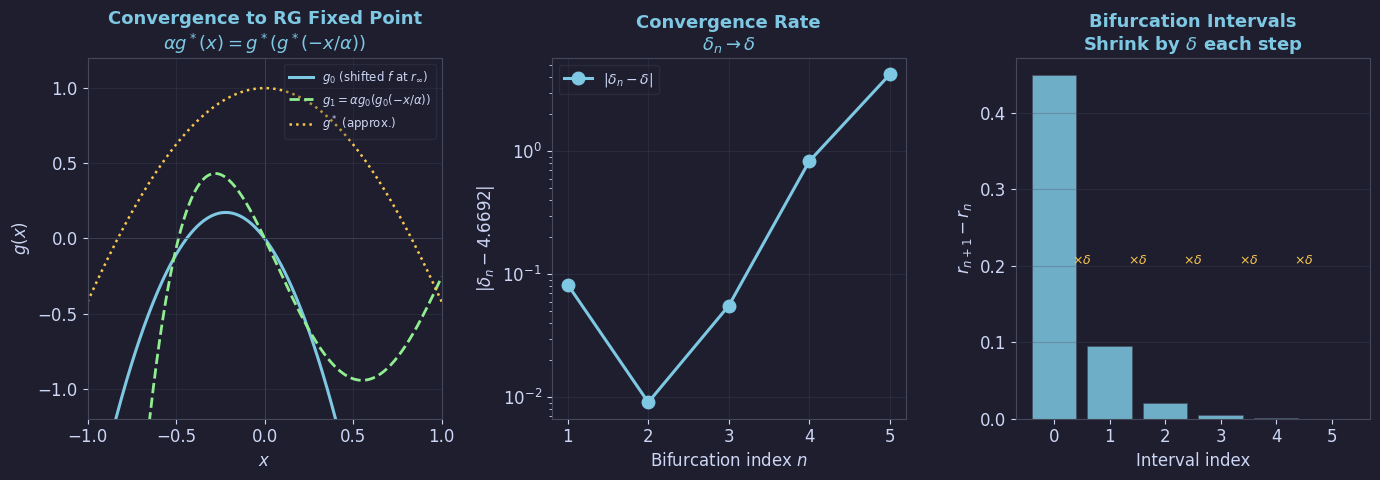

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig05: RG fixed point + delta convergence (§2.3) ─────────────────────
r_inf=3.56995; alpha_F=2.5029
x_star=1-1/r_inf

def f_log(x): return r_inf*x*(1-x)
def g0(x): return f_log(x+x_star)-x_star
def g1(x):
    inner=-x/alpha_F
    return alpha_F*g0(g0(inner))

r_n=[3.0,3.4495,3.5441,3.5644,3.5688,3.5696,3.56969]
deltas=[(r_n[i]-r_n[i-1])/(r_n[i+1]-r_n[i]) for i in range(1,len(r_n)-1)]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

x_plot=np.linspace(-1,1,400)
ax=axes[0]
ax.plot(x_plot,g0(x_plot),color=BLUE,lw=2.2,label='$g_0$ (shifted $f$ at $r_\\infty$)')
ax.plot(x_plot,g1(x_plot),color=GREEN,lw=2.0,ls='--',
        label='$g_1=\\alpha g_0(g_0(-x/\\alpha))$')
g_star=1-1.5276*x_plot**2+0.1048*x_plot**4
ax.plot(x_plot,g_star,color=YELLOW,lw=1.8,ls=':',label='$g^*$ (approx.)')
ax.axhline(0,color=EDGE,lw=0.5); ax.axvline(0,color=EDGE,lw=0.5)
ax.set_xlabel('$x$'); ax.set_ylabel('$g(x)$')
ax.set_title('Convergence to RG Fixed Point\n'+
             r'$\alpha g^*(x)=g^*(g^*(-x/\alpha))$', color=BLUE)
ax.legend(loc="upper right", fontsize=8.5,labelcolor=FG); ax.grid(True)
ax.set_xlim(-1,1); ax.set_ylim(-1.2,1.2)

ax2=axes[1]
ax2.semilogy(list(range(1,len(deltas)+1)),
             [abs(d-4.6692) for d in deltas],
             color=BLUE,lw=2.2,marker='o',ms=9,label='$|\\delta_n-\\delta|$')
ax2.set_xlabel('Bifurcation index $n$')
ax2.set_ylabel('$|\\delta_n-4.6692|$')
ax2.set_title('Convergence Rate\n'+r'$\delta_n\to\delta$', color=BLUE)
ax2.legend(fontsize=10,labelcolor=FG); ax2.grid(True)

ax3=axes[2]
intervals=[r_n[i+1]-r_n[i] for i in range(len(r_n)-1)]
ax3.bar(range(len(intervals)),intervals,color=BLUE,alpha=0.85,
        edgecolor=EDGE,linewidth=0.5)
for i in range(len(intervals)-1):
    ax3.text(i+0.5,max(intervals)*0.45,r'$\times\delta$',
             ha='center',fontsize=9,color=YELLOW)
ax3.set_xlabel('Interval index')
ax3.set_ylabel('$r_{n+1}-r_n$')
ax3.set_title('Bifurcation Intervals\nShrink by $\\delta$ each step', color=BLUE)
ax3.grid(True,axis='y')
plt.tight_layout(pad=1.2)
save('fig05_rg_feigenbaum.png', fig)


---
## Download All Figures

In [6]:
import os, zipfile
from google.colab import files

OUTDIR = 'figures/ch02'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')]) \
        if os.path.exists(OUTDIR) else []
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')
zip_name = 'mathbio_ch02_figures.zip'
with zipfile.ZipFile(zip_name,'w',zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 5 figures:
  fig01_fixedpts_cobweb.png  (221 KB)
  fig02_bifurcation_lyapunov.png  (377 KB)
  fig03_feigenbaum.png  (673 KB)
  fig04_period3.png  (671 KB)
  fig05_rg_feigenbaum.png  (160 KB)
Zip: mathbio_ch02_figures.zip  (2051 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>